In [ ]:
"mean_LSED" # mean annual lake area
'sen_slope_LSED' # trends of annual lake area
"ERA_TAS"   # MAAT from ERA land
"ERA_PER"  #  mean annual PER from ERA land;Territerrestrial water balance,PER= pricipitation-evapotransition-runoff
'ERA_PER_slope' # trends of  annual PER

"Grid_Area"      # Surface area of each grid
"Pf_mean"        # Mean annual ground temperature
['ICE','oDEM','oStd', 'Soil_sand','Soil_silt','Soil_SGU']  #Ground ICE content, Elevation, terrain relief,  Sand content, Silt content,Soil_SGU: GUM_sediment 
['LGM','peatlands','GLiM'] # Last glacier maximum, Peatlands extent, Global Lithological Map

'ITEA' # Individual treatment effects of MAAT on lake area
'ITED' # Individual treatment effects of MAAT on lake drainage
'ITES' # Individual treatment effects of MAAT's trend on lake-area trends
'ITEx_u','ITEx_d' are the upper and lower bounds of the confidence interval for ITEx
'.geo' # grid_geometry

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from econml.dml import CausalForestDML

# ---- 路径 ----
DATA_PATH = r'D:\Python39\Code-NG13\data\Data_all.csv'
OUT_DIR   = r'D:\Python39\Code-NG13\results'
ITE_CSV   = os.path.join(OUT_DIR, 'ITE_ALL.csv')
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 666
np.random.seed(SEED)

# ---- 变量 ----
COL_T    = "ERA_TAS"
COL_GRID = "Grid_Area"
X_COMMON   = ['ICE', 'oDEM', 'oStd', 'ERA_PER',
              'Soil_sand', 'Soil_silt', 'Soil_SGU']
X_CATEGORY = ['LGM', 'peatlands', 'GLiM']

# ---- 三种因果效应的面积处理模式 ----
#   ITEA = ∂mean_LSED / ∂ERA_TAS              → km² / °C
#   ITED = ∂Drainage / ∂ERA_TAS               → % / °C   （Drainage 本身为 per-cell 量）
#   ITES = ∂sen_slope_LSED / ∂ERA_TAS_slope   → km² / °C   （湖泊变化速率 ÷ 温度速率）

CFG_LSED = dict(col_y='mean_LSED', x_num=X_COMMON,
                y_coef=1.0, area_mode='grid')

CFG_DRAIN = dict(col_y='Drainage', x_num=X_COMMON + ['ERA_PER_slope'],
                 y_coef=1.0, area_mode='none')

CFG_TREND_SLOPE = dict(col_y='sen_slope_LSED',
                       x_num=['Lake_density'] + X_COMMON + ['ERA_PER_slope'],
                       y_coef=1.0, col_t='ERA_TAS_slope',
                       area_mode='uniform')

DML_COLS = list({CFG_LSED['col_y'], CFG_DRAIN['col_y'], CFG_TREND_SLOPE['col_y'],
                 COL_T, 'ERA_TAS_slope', COL_GRID, 'ERA_PER', 'Lake_density',
                 'ERA_PER_slope', 'ICE', 'oDEM', 'oStd',
                 'Soil_sand', 'Soil_silt', 'Soil_SGU',
                 'LGM', 'peatlands', 'GLiM'})

class ZeroPreservingScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = np.asarray(X)
        self.max_abs_ = np.max(np.abs(X), axis=0) if X.ndim > 1 else np.max(np.abs(X))
        self.max_abs_ = np.asarray(self.max_abs_)
        self.max_abs_[self.max_abs_ == 0] = 1.0
        return self
    def transform(self, X):
        return np.asarray(X) / self.max_abs_
    def inverse_transform(self, X):
        return np.asarray(X) * self.max_abs_


def fit_causal_forest(data, col_y, x_num, x_cat=X_CATEGORY, y_coef=1.0,
                      seed=SEED, tag="", col_t=COL_T,
                      area_mode='none', uniform_area=None,
                      return_density_effect=False):

    print(f"  ── 拟合 {tag} (Y={col_y}×{y_coef}, T={col_t}, area_mode={area_mode}) n={len(data):,}")
    grid_area = data[COL_GRID].values.astype(float)

    # Y 预处理：按 area_mode 决定面积归一化方式
    if area_mode == 'grid':
        y_raw = (data[col_y].values / grid_area) * y_coef
        area_scale = grid_area
    elif area_mode == 'uniform':
        if uniform_area is None:
            raise ValueError("area_mode='uniform' 需要指定 uniform_area")
        y_raw = (data[col_y].values / uniform_area) * y_coef
        area_scale = np.full(len(data), float(uniform_area))
    elif area_mode == 'none':
        y_raw = data[col_y].values * y_coef
        area_scale = np.ones(len(data), dtype=float)
    else:
        raise ValueError(f"未知 area_mode: {area_mode}")

    scaler_Y = ZeroPreservingScaler().fit(y_raw.reshape(-1, 1))
    y_scaled = scaler_Y.transform(y_raw.reshape(-1, 1)).flatten()
    scaler_T = ZeroPreservingScaler().fit(data[col_t].values.reshape(-1, 1))
    T_scaled = scaler_T.transform(data[col_t].values.reshape(-1, 1)).flatten()

    preprocessor = ColumnTransformer(
        transformers=[('num', ZeroPreservingScaler(), x_num)],
        remainder='passthrough')
    W_processed = preprocessor.fit_transform(data[x_num + x_cat].copy())

    model = CausalForestDML(
        model_y=RandomForestRegressor(n_estimators=100, random_state=seed,
                                      n_jobs=-1, min_samples_leaf=20),
        model_t=RandomForestRegressor(n_estimators=100, random_state=seed,
                                      n_jobs=-1, min_samples_leaf=20),
        n_estimators=200, max_depth=8, min_samples_leaf=20, random_state=seed)
    model.fit(X=W_processed, T=T_scaled, Y=y_scaled)

    ite_s = model.effect(W_processed).flatten()
    lo_s, hi_s = model.effect_interval(W_processed, alpha=0.05)
    lo_s = lo_s.flatten(); hi_s = hi_s.flatten()

    coef = scaler_Y.max_abs_[0] / scaler_T.max_abs_[0]

    if return_density_effect:
        ite = ite_s * coef
        lo  = lo_s  * coef
        hi  = hi_s  * coef
        print(f"     [保留单位面积效应] ITE [{ite.min():.4g}, {ite.max():.4g}]")
    else:
        ite = ite_s * coef * area_scale
        lo  = lo_s  * coef * area_scale
        hi  = hi_s  * coef * area_scale
        print(f"     ITE [{ite.min():.4g}, {ite.max():.4g}]")

    sig = (lo > 0) | (hi < 0)
    print(f"     显著 {sig.mean():.1%}")
    return ite, lo, hi, sig


# ---- 主流程 ----
if __name__ == '__main__':
    print("===== 加载数据并统一筛选 =====")
    df_all = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
    df_all['Lake_density'] = df_all['mean_LSED'] / df_all['Grid_Area']

    data = df_all.dropna(subset=DML_COLS).copy().reset_index(drop=True)
    print(f"统一筛选后样本数: {len(data):,}")

    if data[DML_COLS].isna().sum().sum() > 0:
        raise ValueError("仍有 NaN，请检查 DML_COLS 或数据源")

    print("\n===== DML #1：ITEA（各格面积归一化 → 乘回总量） =====")
    ITEA, ITEA_d, ITEA_u, _ = fit_causal_forest(data, **CFG_LSED, tag="ITEA")

    print("\n===== DML #2：ITED（不除面积 → 保持 per-cell 单位） =====")
    ITED, ITED_d, ITED_u, _ = fit_causal_forest(data, **CFG_DRAIN, tag="ITED")

    print("\n===== DML #3：ITES（统一面积归一化 → 乘回统一面积） =====")
    UNIFORM_AREA = float(data['Grid_Area'].median())
    print(f"  统一网格面积 A0（中位数） = {UNIFORM_AREA:.4f} km²")
    ITES, ITES_d, ITES_u, _ = fit_causal_forest(
        data, **CFG_TREND_SLOPE, tag="ITES", uniform_area=UNIFORM_AREA
    )

    out = pd.DataFrame({
        'ERA_TAS':       data['ERA_TAS'].values,
        'ERA_TAS_slope': data['ERA_TAS_slope'].values,
        'Lake_density':  data['Lake_density'].values,
        'Basin':         data['Basin'].fillna('').values if 'Basin' in data.columns else '',
        'ICE':           data['ICE'].values,
        'Grid_Area':     data['Grid_Area'].values,
        '.geo':          data['.geo'].fillna('').values if '.geo' in data.columns else '',
        'ITEA':   ITEA,   'ITEA_u': ITEA_u,   'ITEA_d': ITEA_d,
        'ITED':   ITED,   'ITED_u': ITED_u,   'ITED_d': ITED_d,
        'ITES':   ITES,   'ITES_u': ITES_u,   'ITES_d': ITES_d,
    })
    out.to_csv(ITE_CSV, index=False, encoding='utf-8-sig')
    print(f"\nCSV 已保存: {ITE_CSV}")
    print("单位说明：")
    print("  ITEA = ∂mean_LSED/∂ERA_TAS            [km² / °C]")
    print("  ITED = ∂Drainage/∂ERA_TAS             [% / °C]")
    print("  ITES = ∂sen_slope_LSED/∂ERA_TAS_slope [km² / °C]  (湖泊变化速率 ÷ 温度速率)")

===== 加载数据并统一筛选 =====
统一筛选后样本数: 82,608

===== DML #1：ITEA（各格面积归一化 → 乘回总量） =====
  ── 拟合 ITEA (Y=mean_LSED×1.0, T=ERA_TAS, area_mode=grid) n=82,608
     ITE [-1.555, 3.803]
     显著 44.8%

===== DML #2：ITED（不除面积 → 保持 per-cell 单位） =====
  ── 拟合 ITED (Y=Drainage×1.0, T=ERA_TAS, area_mode=none) n=82,608
     ITE [-0.0199, 0.05568]
     显著 12.5%

===== DML #3：ITES（统一面积归一化 → 乘回统一面积） =====
  统一网格面积 A0（中位数） = 49.0056 km²
  ── 拟合 ITES (Y=sen_slope_LSED×1.0, T=ERA_TAS_slope, area_mode=uniform) n=82,608
     ITE [-0.42, 0.3551]
     显著 24.6%

CSV 已保存: D:\Python39\Code-NG13\results\ITE_ALL.csv
单位说明：
  ITEA = ∂mean_LSED/∂ERA_TAS            [km² / °C]
  ITED = ∂Drainage/∂ERA_TAS             [% / °C]
  ITES = ∂sen_slope_LSED/∂ERA_TAS_slope [km² / °C]  (湖泊变化速率 ÷ 温度速率)


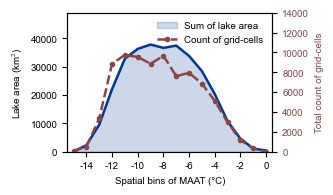

=== 数据统计信息 ===
总样本量：82608
未筛选数据总累加面积：314259.95 km²
筛选后数据总累加面积：314259.95 km²
筛选后面积占比：100.00%
单分箱最大网格单元数量：9743

矢量SVG已保存至：D:\Python39\Code-NG13\results\F1d.svg


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator

# ===================== 1. 全局配置 =====================
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "legend.fontsize": 7,
}
rcParams.update(config)

df = pd.read_csv(r'D:\Python39\Code-NG13\data\Data_all.csv').copy()
fig_path = r"D:\Python39\Code-NG13\results\F1d.svg"

# ===================== 2. 核心函数（平滑函数） =====================
def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

# ===================== 3. 数据读取与预处理 =====================
df_hist_original = df[(df['Perm-region'] == 1)]

bins = np.arange(-17, 3, 1)

# ===================== 4. 处理未筛选数据 =====================
df_unfiltered = df_hist_original.copy()
total_samples = len(df_unfiltered)

df_unfiltered['Area_mean_weighted'] = df_unfiltered['mean_LSED']
df_unfiltered['TAS_bin'] = pd.cut(df_unfiltered['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_unfiltered['TAS_bin_label'] = df_unfiltered['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_unfiltered = df_unfiltered.dropna(subset=['TAS_bin_label']).copy()
df_unfiltered['TAS_bin_label'] = df_unfiltered['TAS_bin_label'].astype(int)

binned_unfiltered = df_unfiltered.groupby('TAS_bin_label', observed=True).agg(
    area_sum=('Area_mean_weighted', 'sum'),
    sample_count=('TAS_bin_label', 'count')
).reset_index().sort_values('TAS_bin_label')

binned_unfiltered = binned_unfiltered[
    (binned_unfiltered['TAS_bin_label'] >= -16) & (binned_unfiltered['TAS_bin_label'] <= 2)
].sort_values('TAS_bin_label').reset_index(drop=True)

binned_unfiltered['area_sum_smooth'] = simple_smooth(binned_unfiltered['area_sum'], window=3)
binned_unfiltered['grid_number'] = binned_unfiltered['sample_count']

# ===================== 5. 处理筛选后数据 =====================
df_filtered = df_hist_original[(df_hist_original['ERA_TAS'] > -16)].copy()
df_filtered['Area_mean_weighted'] = df_filtered['mean_LSED']

df_filtered['TAS_bin'] = pd.cut(df_filtered['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_filtered['TAS_bin_label'] = df_filtered['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_filtered = df_filtered.dropna(subset=['TAS_bin_label']).copy()
df_filtered['TAS_bin_label'] = df_filtered['TAS_bin_label'].astype(int)

binned_filtered = df_filtered.groupby('TAS_bin_label', observed=True).agg(
    area_sum=('Area_mean_weighted', 'sum')
).reset_index().sort_values('TAS_bin_label')

binned_filtered = binned_filtered[
    (binned_filtered['TAS_bin_label'] >= -16) & (binned_filtered['TAS_bin_label'] <= 2)
].sort_values('TAS_bin_label').reset_index(drop=True)

binned_filtered['area_sum_smooth'] = simple_smooth(binned_filtered['area_sum'], window=3)

# ===================== 6. 数据对齐 =====================
merged_data = pd.merge(
    binned_unfiltered[['TAS_bin_label', 'area_sum_smooth', 'grid_number']].rename(
        columns={'area_sum_smooth': 'unfiltered'}),
    binned_filtered[['TAS_bin_label', 'area_sum_smooth']].rename(
        columns={'area_sum_smooth': 'filtered'}),
    on='TAS_bin_label',
    how='outer'
).fillna(0).sort_values('TAS_bin_label')

# ===================== 7. 绘制双轴图 =====================
fig_width_cm = 8.5
fig_height_cm = 5
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax = plt.gca()
plt.subplots_adjust(left=0.18, right=0.82, top=0.88, bottom=0.18)

ax.fill_between(
    merged_data['TAS_bin_label'],
    merged_data['unfiltered'],
    0,
    color='#003994',
    alpha=0.2,
    label='Sum of lake area'
)
ax.plot(
    merged_data['TAS_bin_label'],
    merged_data['unfiltered'],
    color='#003994',
    linewidth=1.8,
    zorder=5
)

ax2 = ax.twinx()
ax2.plot(
    merged_data['TAS_bin_label'],
    merged_data['grid_number'],
    color='#8B4545',
    linewidth=1.8,
    linestyle='--',
    marker='o',
    markersize=3,
    label='Count of grid-cells'
)

# ===================== 8. 双轴样式设置 =====================
ax.set_ylim(bottom=0, top=49000)
ax.set_xlabel('Spatial bins of MAAT (°C)', fontsize=7)
ax.set_xlim(-15.5, 0.5)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.set_ylabel('Lake area (km$^{2}$)', color='black', fontsize=7)
ax.tick_params(axis='y', labelcolor='black', labelsize=7)
ax.tick_params(axis='x', labelsize=7)

ax2.set_ylim(0, 14000)
ax2.set_ylabel('Total count of grid-cells', color='#8B4545', fontsize=7)
ax2.tick_params(axis='y', labelcolor='#8B4545', labelsize=7)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=False, fontsize=7)

# ===================== 9. 输出SVG矢量图 =====================
plt.tight_layout()
plt.savefig(fig_path, format="svg", bbox_inches="tight")
plt.show()
plt.close()

# ===================== 10. 输出统计 =====================
print("=== 数据统计信息 ===")
print(f"总样本量：{total_samples}")
print(f"未筛选数据总累加面积：{merged_data['unfiltered'].sum():.2f} km²")
print(f"筛选后数据总累加面积：{merged_data['filtered'].sum():.2f} km²")
print(f"筛选后面积占比：{merged_data['filtered'].sum()/merged_data['unfiltered'].sum()*100:.2f}%")
print(f"单分箱最大网格单元数量：{merged_data['grid_number'].max():.0f}")
print(f"\n矢量SVG已保存至：{fig_path}")

原始行数: 82,608
列名: ['dx', 'dy', '.geo', 'mean_LSED', 'sen_slope_LSED', 'Pf_mean', 'Basin', 'drainage_flag', 'drainage_count', 'Drainage_count', 'GLDAS_PER_slope', 'BasinID', 'ERA_TAS', 'ERA_PER', 'ICE', 'GLDAS_PER', 'oDEM', 'oStd', 'GLDAS_TAS', 'Grid_Area', 'peatlands', 'LGM', 'ERA_PER_slope', 'ERA_TAS_slope', 'Soil_sand', 'Soil_silt', 'Soil_SGU', 'GLiM', 'Perm-region', 'Drainage']
'Perm-region 过滤后: 82,608


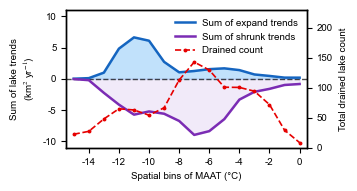


✅ 保存：D:\Python39\Code-NG13\results\F1e.svg
=== 湖泊趋势统计 ===
扩张总量：29.71 km² yr⁻¹
萎缩总量：-62.08 km² yr⁻¹
净变化量：-32.38 km² yr⁻¹
排水湖泊总数（所有网格合计）：1129
含排水湖泊的行数：951


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
import os

# ===================== 1. 全局统一配置 =====================
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "legend.fontsize": 7
}
rcParams.update(config)

f_path     = r'D:\Python39\Code-NG13\data\Data_all.csv'
output_dir = r"D:\Python39\Code-NG13\results"

# ===================== 2. 通用平滑函数 =====================
def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True,
                                   min_periods=1).mean().values

# ===================== 3. 读取数据 =====================
df = pd.read_csv(f_path, low_memory=False, encoding="utf-8-sig")
print(f"原始行数: {len(df):,}")
print(f"列名: {list(df.columns)}")

df = df[(df['Perm-region'] == 1)].copy()
print(f"'Perm-region 过滤后: {len(df):,}")

DRAIN_COL = 'Drainage_count'

# ===================== 4. 温度分箱（-16 ~ 2） =====================
bins = np.arange(-17, 3, 1)   
df['TAS_bin'] = pd.cut(df['ERA_TAS'], bins=bins, right=True,
                       include_lowest=True)
df['TAS_bin_label'] = df['TAS_bin'].apply(
    lambda x: x.right if pd.notna(x) else np.nan
)
df = df.dropna(subset=['TAS_bin_label']).copy()
df['TAS_bin_label'] = df['TAS_bin_label'].astype(int)

slope = df['sen_slope_LSED'].fillna(0)
df['positive_slope'] = np.where(slope >= 0, slope, 0.0)
df['negative_slope'] = np.where(slope <  0, slope, 0.0)

# ===================== 5. 分箱聚合 =====================
binned = df.groupby('TAS_bin_label', observed=True).agg(
    positive_sum    =('positive_slope', 'sum'),
    negative_sum    =('negative_slope', 'sum'),
    drain_count_sum = (DRAIN_COL,      'sum'),
).reset_index().sort_values('TAS_bin_label')

binned = binned[
    (binned['TAS_bin_label'] >= -16) & (binned['TAS_bin_label'] <= 2)
].reset_index(drop=True)

binned['positive_smooth']    = simple_smooth(binned['positive_sum'],    window=3)
binned['negative_smooth']    = simple_smooth(binned['negative_sum'],    window=3)
binned['drain_count_smooth'] = simple_smooth(binned['drain_count_sum'], window=3)

# ===================== 6. 绘图 =====================
fig_width_cm = 8.5
fig_height_cm = 5
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax  = plt.gca()
ax2 = ax.twinx()
plt.subplots_adjust(left=0.16, right=0.88, top=0.92, bottom=0.22)

color_exp_fill   = '#64b5f6'
color_exp_line   = '#1565c0'
color_shr_line   = '#7b2cb4'
color_shr_fill   = '#dcccf2'
color_drain_line = '#e60000'  

line_exp, = ax.plot(
    binned['TAS_bin_label'], binned['positive_smooth'],
    color=color_exp_line, linewidth=1.8, zorder=5
)
ax.fill_between(
    binned['TAS_bin_label'],
    binned['positive_smooth'], 0,
    color=color_exp_fill, alpha=0.4
)

line_shr, = ax.plot(
    binned['TAS_bin_label'], binned['negative_smooth'],
    color=color_shr_line, linewidth=1.8, zorder=5
)
ax.fill_between(
    binned['TAS_bin_label'],
    binned['negative_smooth'], 0,
    color=color_shr_fill, alpha=0.4
)

ax.axhline(y=0, color='black', linestyle='--', alpha=0.7, linewidth=1)

line_drain_count, = ax2.plot(
    binned['TAS_bin_label'], binned['drain_count_smooth'],
    color=color_drain_line, linewidth=1.2, linestyle='--',
    marker='o', markersize=1.8
)

# ===================== 7. 坐标轴 =====================
ax.set_xlabel('Spatial bins of MAAT (°C)', fontsize=7)
ax.set_ylabel(r"Sum of lake trends" + "\n" + r"(km$^{2}$ yr$^{-1}$)",
              color='black', fontsize=7)
ax.set_xlim(-15.5, 0.5)         
ax.set_ylim(-11, 11)
ax.tick_params(axis='both', labelsize=7)
ax.xaxis.set_major_locator(MultipleLocator(2))

ax2.set_ylabel('Total drained lake count', color='black', fontsize=7)
ax2.tick_params(axis='y', labelsize=7)
ax2.set_ylim(0, 230)
ax2.grid(False)

# ===================== 8. 合并图例 =====================
handles = [line_exp, line_shr, line_drain_count]
labels = ['Sum of expand trends', 'Sum of shrunk trends', 'Drained count']

ax.legend(
    handles=handles,
    labels=labels,
    loc='upper right', frameon=False, fontsize=7
)

for spine in ax.spines.values():
    spine.set_linewidth(1)
for spine in ax2.spines.values():
    spine.set_linewidth(1)

# ===================== 9. 导出 =====================
os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "F1e.svg")
plt.savefig(save_path, format="svg")
plt.show()
plt.close()

# ===================== 10. 控制台输出 =====================
print(f"\n✅ 保存：{save_path}")
print("=== 湖泊趋势统计 ===")
print(f"扩张总量：{binned['positive_sum'].sum():.2f} km² yr⁻¹")
print(f"萎缩总量：{binned['negative_sum'].sum():.2f} km² yr⁻¹")
print(f"净变化量：{binned['positive_sum'].sum() + binned['negative_sum'].sum():.2f} km² yr⁻¹")
print(f"排水湖泊总数（所有网格合计）：{binned['drain_count_sum'].sum():.0f}")
print(f"含排水湖泊的行数：{(df[DRAIN_COL] > 0).sum():,}")

===== 读取数据 =====
F2c ...

  【ITEA 累积曲线过零点】
    pos→neg: T*=-9.14°C, 95% CI=[-11.07, -7.21]


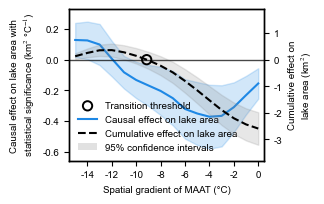

  F2c 完成: D:\Python39\Code-NG13\results\F2c.svg


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
from matplotlib.patches import Patch
from scipy.stats import norm

# ---- 路径 ----
ITE_CSV   = r'D:\Python39\Code-NG13\results\ITE_ALL.csv'
OUT_DIR   = r'D:\Python39\Code-NG13\results'
os.makedirs(OUT_DIR, exist_ok=True)

# ---- 全局样式 ----
rcParams.update({
    "font.family": 'Arial', "font.size": 7, "axes.labelsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.unicode_minus": False,
    "mathtext.fontset": 'stix', "figure.dpi": 100, "savefig.dpi": 300,
    "legend.fontsize": 7, "svg.fonttype": "path"
})

bins = np.arange(-17, 3, 1)


def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True,
                                   min_periods=1).mean().values


def build_binned_stats(df_sub, y_col, lo_col, hi_col,
                       maat_range=(-16, 2), n_bins_step=1.0):
    d = df_sub.copy()
    if len(d) < 20:
        return None
    bins_t = np.arange(maat_range[0] - 1, maat_range[1] + 2, n_bins_step)
    d['TAS_bin'] = pd.cut(d['ERA_TAS'], bins=bins_t, right=True, include_lowest=True)
    d['TAS_bin_label'] = d['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
    d = d.dropna(subset=['TAS_bin_label']).copy()
    if len(d) == 0:
        return None
    d['TAS_bin_label'] = d['TAS_bin_label'].astype(int)
    b = d.groupby('TAS_bin_label', observed=True).agg(
        total_mean=(y_col, 'mean'),
        total_lower_mean=(lo_col, 'mean'),
        total_upper_mean=(hi_col, 'mean'),
        n=(y_col, 'size'),
    ).reset_index().sort_values('TAS_bin_label')
    b = b[(b['TAS_bin_label'] >= maat_range[0]) &
          (b['TAS_bin_label'] <= maat_range[1])].reset_index(drop=True)
    if len(b) < 2:
        return None
    b['total_mean_smooth']       = simple_smooth(b['total_mean'], 3)
    b['total_lower_mean_smooth'] = simple_smooth(b['total_lower_mean'], 3)
    b['total_upper_mean_smooth'] = simple_smooth(b['total_upper_mean'], 3)
    b['cumsum'] = b['total_mean_smooth'].cumsum()
    se = np.clip((b['total_upper_mean_smooth'] - b['total_lower_mean_smooth']) / (2*1.96),
                 1e-12, None)
    se_cum = np.sqrt((se ** 2).cumsum())
    b['cumsum_lo'] = b['cumsum'] - 1.96 * se_cum
    b['cumsum_hi'] = b['cumsum'] + 1.96 * se_cum
    return b


def fieller_zero_cross_with_ci(binned_stats, mean_col='total_mean_smooth',
                                lo_col='total_lower_mean_smooth',
                                hi_col='total_upper_mean_smooth',
                                search_min=-16, search_max=2,
                                direction='neg_to_pos', alpha=0.05):
    df = binned_stats.copy()
    df['TAS_bin_label'] = pd.to_numeric(df['TAS_bin_label'], errors='coerce')
    df = df[(df['TAS_bin_label'] >= float(search_min)) &
            (df['TAS_bin_label'] <= float(search_max))] \
        .sort_values('TAS_bin_label').reset_index(drop=True)
    if len(df) < 2:
        return None, None, None
    x_vals = df['TAS_bin_label'].values.astype(float)
    mean_vals = df[mean_col].values
    lo_vals = df[lo_col].values
    hi_vals = df[hi_col].values
    cumsum = np.cumsum(mean_vals)
    se_bin = np.clip((hi_vals - lo_vals) / (2 * 1.96), 1e-12, None)
    se_cumsum = np.sqrt(np.cumsum(se_bin ** 2))
    z = norm.ppf(1 - alpha / 2)
    for i in range(len(df) - 1):
        y1, y2 = cumsum[i], cumsum[i + 1]
        if np.sign(y1) == np.sign(y2):
            continue
        if direction == 'neg_to_pos' and not (y1 < 0 and y2 > 0):
            continue
        if direction == 'pos_to_neg' and not (y1 > 0 and y2 < 0):
            continue
        x1, x2 = x_vals[i], x_vals[i + 1]
        T_star = x1 - y1 * (x2 - x1) / (y2 - y1)
        SE_at_T = float(np.interp(T_star, x_vals, se_cumsum))
        F_prime = float(np.interp(T_star, x_vals, mean_vals))
        if abs(F_prime) < 1e-10:
            return T_star, None, None
        se_T = SE_at_T / abs(F_prime)
        return T_star, T_star - z * se_T, T_star + z * se_T
    return None, None, None


def fieller_zero_cross_bidirectional(binned_stats, mean_col, lo_col, hi_col,
                                      search_min=-16, search_max=2, alpha=0.05):
    results = []
    for direction in ['pos_to_neg', 'neg_to_pos']:
        T, T_lo, T_hi = fieller_zero_cross_with_ci(
            binned_stats, mean_col, lo_col, hi_col,
            search_min, search_max, direction, alpha)
        if T is not None:
            results.append(dict(direction=direction, T=T, T_lo=T_lo, T_hi=T_hi))
    return results


# ---- 执行绘图 ----
print("===== 读取数据 =====")
df_ite = pd.read_csv(ITE_CSV, encoding='utf-8-sig')

print("F2c ...")
df_h = df_ite[~((df_ite['ITEA_d'] < 0) & (df_ite['ITEA_u'] > 0))].copy()
df_h['TAS_bin'] = pd.cut(df_h['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_h['TAS_bin_label'] = df_h['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_h = df_h.dropna(subset=['TAS_bin_label']).copy()
df_h['TAS_bin_label'] = df_h['TAS_bin_label'].astype(int)

b_ = build_binned_stats(df_h, 'ITEA', 'ITEA_d', 'ITEA_u')

crs = fieller_zero_cross_bidirectional(
    b_, 'total_mean_smooth', 'total_lower_mean_smooth', 'total_upper_mean_smooth')

print("\n  【ITEA 累积曲线过零点】")
for cr in crs:
    label = 'pos→neg' if cr['direction'] == 'pos_to_neg' else 'neg→pos'
    if cr['T_lo'] is not None:
        print(f"    {label}: T*={cr['T']:.2f}°C, 95% CI=[{cr['T_lo']:.2f}, {cr['T_hi']:.2f}]")

fig = plt.figure(figsize=(8/2.54, 5.5/2.54))
ax = plt.gca(); ax_r = ax.twinx()
plt.subplots_adjust(left=0.19, right=0.81, top=0.92, bottom=0.22)

sum_line, = ax.plot(b_['TAS_bin_label'], b_['total_mean_smooth'],
                    '-', color='#1e88e5', linewidth=1.5, label='Causal effect')
ax.fill_between(b_['TAS_bin_label'], b_['total_lower_mean_smooth'],
                b_['total_upper_mean_smooth'], color='#1e88e5', alpha=0.2)

cum_line, = ax_r.plot(b_['TAS_bin_label'], b_['cumsum'],
                      '--', color='black', linewidth=1.5, label='Cumulative effect',
                      zorder=3)
ax_r.fill_between(b_['TAS_bin_label'], b_['cumsum_lo'], b_['cumsum_hi'],
                  color='#888888', alpha=0.2, zorder=1)

mm = None
for cr in crs:
    mm = ax_r.scatter(cr['T'], 0, edgecolor='black', facecolor='none',
                      s=45, linewidth=1.4, marker='o', zorder=10)
    break

ax.set_ylabel('Causal effect on lake area with\n statistical significance (km$^{2}$ °C$^{-1}$)')
ax_r.set_ylabel('Cumulative effect on\nlake area (km$^{2}$)', color='black')  
ax.set_xlabel('Spatial gradient of MAAT (°C)')
ax.set_xlim(-15.5, 0.5)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.set_ylim(-0.66, 0.33)
ax_r.set_ylim(-3.8, 1.9)

ax.axhline(y=0, color='black', linestyle='-', alpha=0.3, zorder=1, linewidth=0.8)
ax_r.axhline(y=0, color='black', linestyle='-', alpha=0.6, zorder=2, linewidth=1.0)  

le = [sum_line, cum_line, Patch(facecolor='#888888', alpha=0.25)]
ll = ['Causal effect on lake area', 'Cumulative effect on lake area', '95% confidence intervals']
if mm is not None:
    le.insert(0, mm); ll.insert(0, 'Transition threshold')

ax.legend(le, ll, loc='lower left', frameon=False)
for sp in ax.spines.values(): sp.set_linewidth(1)
for sp in ax_r.spines.values(): sp.set_linewidth(1)

save_path = os.path.join(OUT_DIR, "F2c.svg")
plt.savefig(save_path, format="svg")
plt.show()
plt.close()
print(f"  F2c 完成: {save_path}")

===== 读取数据 =====
F2d ...

  【ITED 均值对比（% °C⁻¹）】
    全结果   n=82608  均值 = +0.1398
    显著性   n=10294  均值 = +0.2309

  【ITED 累积曲线过零点】
    [neg→pos] T*=-11.54°C, 95% CI=[-14.52, -8.56]


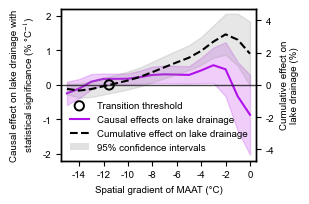

  F2d 完成: D:\Python39\Code-NG13\results\F2d.svg


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
from matplotlib.patches import Patch
from scipy.stats import norm

ITE_CSV = r'D:\Python39\Code-NG13\results\ITE_ALL.csv'
OUT_DIR = r'D:\Python39\Code-NG13\results'
os.makedirs(OUT_DIR, exist_ok=True)

rcParams.update({
    "font.family": 'Arial', "font.size": 7, "axes.labelsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.unicode_minus": False,
    "mathtext.fontset": 'stix', "figure.dpi": 100, "savefig.dpi": 300,
    "legend.fontsize": 7, "svg.fonttype": "path"
})

bins = np.arange(-17, 3, 1)


def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True,
                                   min_periods=1).mean().values


def build_binned_stats(df_sub, y_col, lo_col, hi_col,
                       maat_range=(-16, 2), n_bins_step=1.0):
    d = df_sub.copy()
    if len(d) < 20:
        return None
    bins_t = np.arange(maat_range[0] - 1, maat_range[1] + 2, n_bins_step)
    d['TAS_bin'] = pd.cut(d['ERA_TAS'], bins=bins_t, right=True, include_lowest=True)
    d['TAS_bin_label'] = d['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
    d = d.dropna(subset=['TAS_bin_label']).copy()
    if len(d) == 0:
        return None
    d['TAS_bin_label'] = d['TAS_bin_label'].astype(int)
    b = d.groupby('TAS_bin_label', observed=True).agg(
        total_mean=(y_col, 'mean'),
        total_lower_mean=(lo_col, 'mean'),
        total_upper_mean=(hi_col, 'mean'),
        n=(y_col, 'size'),
    ).reset_index().sort_values('TAS_bin_label')
    b = b[(b['TAS_bin_label'] >= maat_range[0]) &
          (b['TAS_bin_label'] <= maat_range[1])].reset_index(drop=True)
    if len(b) < 2:
        return None
    b['total_mean_smooth']       = simple_smooth(b['total_mean'], 3)
    b['total_lower_mean_smooth'] = simple_smooth(b['total_lower_mean'], 3)
    b['total_upper_mean_smooth'] = simple_smooth(b['total_upper_mean'], 3)
    b['cumsum'] = b['total_mean_smooth'].cumsum()
    se = np.clip((b['total_upper_mean_smooth'] - b['total_lower_mean_smooth']) / (2 * 1.96),
                 1e-12, None)
    se_cum = np.sqrt((se ** 2).cumsum())
    b['cumsum_lo'] = b['cumsum'] - 1.96 * se_cum
    b['cumsum_hi'] = b['cumsum'] + 1.96 * se_cum
    return b


def fieller_zero_cross_with_ci(binned_stats, mean_col='total_mean_smooth',
                                lo_col='total_lower_mean_smooth',
                                hi_col='total_upper_mean_smooth',
                                search_min=-16, search_max=2,
                                direction='neg_to_pos', alpha=0.05):
    df = binned_stats.copy()
    df['TAS_bin_label'] = pd.to_numeric(df['TAS_bin_label'], errors='coerce')
    df = df[(df['TAS_bin_label'] >= float(search_min)) &
            (df['TAS_bin_label'] <= float(search_max))] \
        .sort_values('TAS_bin_label').reset_index(drop=True)
    if len(df) < 2:
        return None, None, None
    x_vals = df['TAS_bin_label'].values.astype(float)
    mean_vals = df[mean_col].values
    lo_vals = df[lo_col].values
    hi_vals = df[hi_col].values
    cumsum = np.cumsum(mean_vals)
    se_bin = np.clip((hi_vals - lo_vals) / (2 * 1.96), 1e-12, None)
    se_cumsum = np.sqrt(np.cumsum(se_bin ** 2))
    z = norm.ppf(1 - alpha / 2)
    for i in range(len(df) - 1):
        y1, y2 = cumsum[i], cumsum[i + 1]
        if np.sign(y1) == np.sign(y2):
            continue
        if direction == 'neg_to_pos' and not (y1 < 0 and y2 > 0):
            continue
        if direction == 'pos_to_neg' and not (y1 > 0 and y2 < 0):
            continue
        x1, x2 = x_vals[i], x_vals[i + 1]
        T_star = x1 - y1 * (x2 - x1) / (y2 - y1)
        SE_at_T = float(np.interp(T_star, x_vals, se_cumsum))
        F_prime = float(np.interp(T_star, x_vals, mean_vals))
        if abs(F_prime) < 1e-10:
            return T_star, None, None
        se_T = SE_at_T / abs(F_prime)
        return T_star, T_star - z * se_T, T_star + z * se_T
    return None, None, None


def fieller_zero_cross_bidirectional(binned_stats, mean_col, lo_col, hi_col,
                                      search_min=-16, search_max=2, alpha=0.05):
    results = []
    for direction in ['pos_to_neg', 'neg_to_pos']:
        T, T_lo, T_hi = fieller_zero_cross_with_ci(
            binned_stats, mean_col, lo_col, hi_col,
            search_min, search_max, direction, alpha)
        if T is not None:
            results.append(dict(direction=direction, T=T, T_lo=T_lo, T_hi=T_hi))
    return results


print("===== 读取数据 =====")
df_ite = pd.read_csv(ITE_CSV, encoding='utf-8-sig')

print("F2d ...")
# 1. ITED 转百分比
df_ite_d = df_ite.copy()
for col in ['ITED', 'ITED_u', 'ITED_d']:
    df_ite_d[col] = df_ite_d[col] * 100.0

df_h = df_ite_d[~((df_ite_d['ITED_d'] < 0) & (df_ite_d['ITED_u'] > 0))].copy()

# ===================== 新增：print 两种均值 =====================
all_mean = float(df_ite_d['ITED'].mean())    
sig_mean = float(df_h['ITED'].mean())         
print("\n  【ITED 均值对比（% °C⁻¹）】")
print(f"    全结果   n={len(df_ite_d):>5d}  均值 = {all_mean:+.4f}")
print(f"    显著性   n={len(df_h):>5d}  均值 = {sig_mean:+.4f}")
# ==============================================================

df_h['TAS_bin'] = pd.cut(df_h['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_h['TAS_bin_label'] = df_h['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_h = df_h.dropna(subset=['TAS_bin_label']).copy()
df_h['TAS_bin_label'] = df_h['TAS_bin_label'].astype(int)

b_ = build_binned_stats(df_h, 'ITED', 'ITED_d', 'ITED_u')

crs = fieller_zero_cross_bidirectional(
    b_, 'total_mean_smooth', 'total_lower_mean_smooth', 'total_upper_mean_smooth')

selected_cr = None
for cr in crs:
    if cr['direction'] == 'neg_to_pos':
        selected_cr = cr
        break
if selected_cr is None and len(crs) > 0:
    selected_cr = crs[0]

print("\n  【ITED 累积曲线过零点】")
if selected_cr is not None:
    d_lbl = 'neg→pos' if selected_cr['direction'] == 'neg_to_pos' else 'pos→neg'
    if selected_cr['T_lo'] is not None:
        print(f"    [{d_lbl}] T*={selected_cr['T']:.2f}°C, "
              f"95% CI=[{selected_cr['T_lo']:.2f}, {selected_cr['T_hi']:.2f}]")
    else:
        print(f"    [{d_lbl}] T*={selected_cr['T']:.2f}°C (CI 发散)")
else:
    print("    未检测到过零点")

fig = plt.figure(figsize=(8 / 2.54, 5.5 / 2.54))
ax = plt.gca()
ax_r = ax.twinx()
plt.subplots_adjust(left=0.19, right=0.81, top=0.92, bottom=0.22)

sum_line, = ax.plot(b_['TAS_bin_label'], b_['total_mean_smooth'],
                    '-', color='#B111EA', linewidth=1.5,
                    label='Causal effect on lake drainage')
ax.fill_between(b_['TAS_bin_label'], b_['total_lower_mean_smooth'],
                b_['total_upper_mean_smooth'], color='#B111EA', alpha=0.2)

cum_line, = ax_r.plot(b_['TAS_bin_label'], b_['cumsum'],
                      '--', color='black', linewidth=1.5,
                      label='Cumulative effect on lake drainage')
ax_r.fill_between(b_['TAS_bin_label'], b_['cumsum_lo'], b_['cumsum_hi'],
                  color='#888888', alpha=0.2)

mm = None
if selected_cr is not None:
    mm = ax_r.scatter(selected_cr['T'], 0, edgecolor='black', facecolor='none',
                      s=45, linewidth=1.4, marker='o', zorder=10)

ax.set_ylabel('Causal effect on lake drainage with\n statistical significance (% °C$^{-1}$)')
ax_r.set_ylabel('Cumulative effect on\nlake drainage (%)')
ax.set_xlabel('Spatial gradient of MAAT (°C)')
ax.set_xlim(-15.5, 0.5)
ax.xaxis.set_major_locator(MultipleLocator(2))

ax.set_ylim(-2.2, 2.2)
ax_r.set_ylim(-4.7, 4.7)

ax.axhline(y=0, color='black', linestyle='-', alpha=0.3, zorder=1, linewidth=0.8)
ax_r.axhline(y=0, color='black', linestyle='-', alpha=0.6, zorder=1, linewidth=1.0)

le = [sum_line, cum_line, Patch(facecolor='#888888', alpha=0.25)]
ll = ['Causal effects on lake drainage', 'Cumulative effect on lake drainage',
      '95% confidence intervals']
if mm is not None:
    le.insert(0, mm)
    ll.insert(0, 'Transition threshold')

ax.legend(le, ll, loc='lower left', frameon=False)
for sp in ax.spines.values():
    sp.set_linewidth(1)
for sp in ax_r.spines.values():
    sp.set_linewidth(1)

save_path = os.path.join(OUT_DIR, "F2d.svg")
plt.savefig(save_path, format="svg")
plt.show()
plt.close()
print(f"  F2d 完成: {save_path}")

===== 读取数据 =====

  【拐点识别：动态阈值法 + Bootstrap CI】
    τ̂ = +0.0367, 动态基准值 = -0.0023
    Bootstrap 95% CI = [+0.0350, +0.0382]


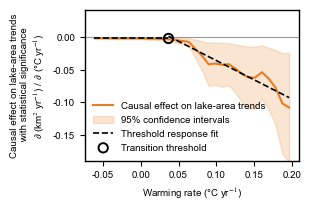


  F2e 完成: D:\Python39\Code-NG13\results\F2e.svg


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# ---- 路径 ----
ITE_CSV   = r'D:\Python39\Code-NG13\results\ITE_ALL.csv'
OUT_DIR   = r'D:\Python39\Code-NG13\results'
os.makedirs(OUT_DIR, exist_ok=True)

# ---- 全局样式 ----
rcParams.update({
    "font.family": 'Arial', "font.size": 7, "axes.labelsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.unicode_minus": False,
    "mathtext.fontset": 'stix', "figure.dpi": 100, "savefig.dpi": 300,
    "legend.fontsize": 7, "svg.fonttype": "path"
})

def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

def build_slope_binned_stats(df_sub, y_col, lo_col, hi_col, n_bins=30):
    d = df_sub.copy().dropna(subset=['ERA_TAS_slope'])
    if len(d) < 50: return None
    s_min, s_max = d['ERA_TAS_slope'].min(), d['ERA_TAS_slope'].max()
    if s_min == s_max: return None
    slope_bins = np.linspace(s_min, s_max, n_bins + 1)
    d['SLOPE_bin'] = pd.cut(d['ERA_TAS_slope'], bins=slope_bins, right=True, include_lowest=True)
    d['SLOPE_bin_label'] = d['SLOPE_bin'].apply(lambda x: 0.5 * (x.left + x.right) if pd.notna(x) else np.nan)
    d['SLOPE_bin_label'] = pd.to_numeric(d['SLOPE_bin_label'], errors='coerce')
    d = d.dropna(subset=['SLOPE_bin_label']).copy()

    b = d.groupby('SLOPE_bin_label', observed=True).agg(
        total_mean=(y_col, 'mean'), total_lower_mean=(lo_col, 'mean'),
        total_upper_mean=(hi_col, 'mean'), n=(y_col, 'size')
    ).reset_index().sort_values('SLOPE_bin_label')
    b = b[b['n'] >= 5].reset_index(drop=True)
    if len(b) < 3: return None
    b['total_mean_smooth']       = simple_smooth(b['total_mean'], 3)
    b['total_lower_mean_smooth'] = simple_smooth(b['total_lower_mean'], 3)
    b['total_upper_mean_smooth'] = simple_smooth(b['total_upper_mean'], 3)
    return b

def find_dynamic_shift_point(binned_stats, k_sigma=1.96):
    if binned_stats is None: return None, None
    x_vals = binned_stats['SLOPE_bin_label'].values.astype(float)
    y_vals = binned_stats['total_mean_smooth'].values.astype(float)
    
    n = len(y_vals)
    init_win = max(4, int(n * 0.15))
    if n < init_win: return None, None
    
    base_y = list(y_vals[:init_win])
    init_std = max(np.std(base_y), 0.0008) 
    
    end_idx = init_win
    for i in range(init_win, n):
        curr_mean = np.mean(base_y)
        thresh = curr_mean - k_sigma * init_std

        if i + 1 < n and y_vals[i] < thresh and y_vals[i+1] < thresh:
            break

        if y_vals[i] < thresh:
            continue
        base_y.append(y_vals[i])
        end_idx = i + 1
        
    if end_idx >= n: return None, None
        

    dynamic_base = np.mean(base_y)
    dynamic_std = np.std(base_y)
    dynamic_thresh = dynamic_base - k_sigma * dynamic_std
    

    for i in range(end_idx, n):
        if y_vals[i] < dynamic_thresh:
            subsequent = y_vals[i:]
            if len(subsequent) >= 3 and np.mean(subsequent < dynamic_thresh) >= 0.75:
                x1, x2 = x_vals[i-1], x_vals[i]
                y1, y2 = y_vals[i-1], y_vals[i]
                if y2 != y1:
                    tau = x1 + (dynamic_thresh - y1) * (x2 - x1) / (y2 - y1)
                    return max(x1, min(x2, tau)), dynamic_base
                else:
                    return x2, dynamic_base
    return None, None

def bootstrap_dynamic_shift(df_sig, y_col, lo_col, hi_col, B=1000, seed=42, n_bins=30):
    rng = np.random.default_rng(seed)
    n = len(df_sig)
    tau_samples = []

    for b in range(B):
        idx = rng.integers(0, n, n)
        sub = df_sig.iloc[idx]
        bs = build_slope_binned_stats(sub, y_col, lo_col, hi_col, n_bins=n_bins)
        if bs is None or len(bs) < 10: continue
        
        t, _ = find_dynamic_shift_point(bs)
        if t is not None and np.isfinite(t):
            tau_samples.append(t)

    tau_samples = np.asarray(tau_samples)
    if len(tau_samples) < 20:
        return None, None, tau_samples
    return float(np.percentile(tau_samples, 2.5)), float(np.percentile(tau_samples, 97.5)), tau_samples

# ==============================================================

print("===== 读取数据 =====")
df_ite = pd.read_csv(ITE_CSV, encoding='utf-8-sig')
sig_mask = ~((df_ite['ITES_d'] < 0) & (df_ite['ITES_u'] > 0))
df_ite_sig = df_ite[sig_mask].copy()

b_s = build_slope_binned_stats(df_ite_sig, 'ITES', 'ITES_d', 'ITES_u')
x_bin = b_s['SLOPE_bin_label'].values.astype(float)
y_bin = b_s['total_mean_smooth'].values.astype(float)


tau_est, dynamic_base = find_dynamic_shift_point(b_s)


B = 1000
ci_lo, ci_hi, tau_samples = bootstrap_dynamic_shift(df_ite_sig, 'ITES', 'ITES_d', 'ITES_u', B=B)

print("\n  【拐点识别：动态阈值法 + Bootstrap CI】")
if tau_est is not None:
    print(f"    τ̂ = {tau_est:+.4f}, 动态基准值 = {dynamic_base:+.4f}")
    if ci_lo is not None:
        print(f"    Bootstrap 95% CI = [{ci_lo:+.4f}, {ci_hi:+.4f}]")
else:
    print("    ⚠ 未检测到显著突变点")

# ==============================================================
fig = plt.figure(figsize=(8 / 2.54, 5.5 / 2.54))
ax = plt.gca()
plt.subplots_adjust(left=0.30, right=0.98, top=0.92, bottom=0.22)

ax.plot(b_s['SLOPE_bin_label'], b_s['total_mean_smooth'],
        '-', color='#e67e22', linewidth=1.5,
        label='Causal effect on lake-area trends')
ax.fill_between(b_s['SLOPE_bin_label'], b_s['total_lower_mean_smooth'],
                b_s['total_upper_mean_smooth'], color='#e67e22', alpha=0.2,
                label='95% confidence intervals')


if tau_est is not None:
    x_l = np.linspace(x_bin.min(), tau_est, 50)
    ax.plot(x_l, np.full_like(x_l, dynamic_base), '--', color='black', linewidth=1.2,
            label='Threshold response fit')
            
    mask_r = x_bin >= tau_est
    if mask_r.sum() >= 2:
        p_r = np.polyfit(x_bin[mask_r], y_bin[mask_r], 1)
        x_r = np.linspace(tau_est, x_bin.max(), 50)
        ax.plot(x_r, np.polyval(p_r, x_r), '--', color='black', linewidth=1.2)

    ax.scatter(tau_est, dynamic_base, edgecolor='black', facecolor='none',
               s=45, linewidth=1.4, marker='o', zorder=10,
               label='Transition threshold')

ax.axhline(0, color='black', linestyle='-', alpha=0.4, zorder=0, linewidth=0.8)

ax.set_xlabel(r'Warming rate (°C yr$^{-1}$)')
ax.set_ylabel('Causal effect on lake-area trends\n with statistical significance\n'
              r'$\partial$ (km$^{2}$ yr$^{-1}$) $/\,$ $\partial$ (°C yr$^{-1}$)')

y_lo = float(np.min(b_s['total_lower_mean_smooth']))
y_hi = float(np.max(b_s['total_upper_mean_smooth']))
pad_y = (y_hi - y_lo) * 0.05 if y_hi > y_lo else 0.1
ax.set_ylim(-0.19, 0.042)

for sp in ax.spines.values():
    sp.set_linewidth(1)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, loc='lower left', frameon=False)

save_path = os.path.join(OUT_DIR, "F2e.svg")
plt.savefig(save_path, format="svg", bbox_inches="tight", pad_inches=0.02)
plt.show()
plt.close()
print(f"\n  F2e 完成: {save_path}")

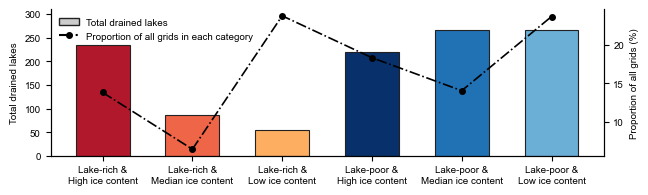

绘图完成，文件保存至：D:\Python39\Code-NG13\results\F3a.svg
全局总网格数（Perm-region == 1）：82608
各组信息：
Lake-rich & High ice content | drained=234, all grids=11397, proportion=13.80%
Lake-rich & Median ice content | drained=87, all grids=5310, proportion=6.43%
Lake-rich & Low ice content | drained=55, all grids=19614, proportion=23.74%
Lake-poor & High ice content | drained=220, all grids=15121, proportion=18.30%
Lake-poor & Median ice content | drained=267, all grids=11584, proportion=14.02%
Lake-poor & Low ice content | drained=266, all grids=19533, proportion=23.65%

===== 全局总体统计 =====
全部网格总数: 82608
排水湖泊总数（Drainage_count 合计）: 1129
排水湖泊数 / 网格数: 1.37 %

===== 各组内部排水密度 =====
Lake-rich & High ice content | drained=234, group grids=11397, drained/grid=2.05 %
Lake-rich & Median ice content | drained=87, group grids=5310, drained/grid=1.64 %
Lake-rich & Low ice content | drained=55, group grids=19614, drained/grid=0.28 %
Lake-poor & High ice content | drained=220, group grids=15121, drained/grid=1.45 %
Lake

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ========== 全局字体设置 ==========
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 7
plt.rcParams["legend.fontsize"] = 7

f_path     = r'D:\Python39\Code-NG13\data\Data_all.csv'
output_dir = r"D:\Python39\Code-NG13\results"

# 每组柱子对应颜色
group_color_map = {
    'Lake-rich &\nHigh ice content':   '#b2182b',
    'Lake-rich &\nMedian ice content': '#ef6548',
    'Lake-rich &\nLow ice content':    '#fdae61',
    'Lake-poor &\nHigh ice content':   '#08306b',
    'Lake-poor &\nMedian ice content': '#2171b5',
    'Lake-poor &\nLow ice content':    '#6baed6',
}

# ===================== 1. 读取数据 =====================
df = pd.read_csv(f_path, low_memory=False, encoding="utf-8-sig")
df_raw = df[(df['Perm-region'] == 1)].copy()

DRAIN_COL = 'Drainage_count'

df_raw['ratio'] = (df_raw['mean_LSED'] / df_raw['Grid_Area'] * 100).values

total_all_grids = len(df_raw)

# ===================== 2. 分组筛选条件 =====================
group_config = {
    'Lake-rich &\nHigh ice content':   {'filter': (df_raw['ratio'] > 5) & (df_raw['ICE'] == 3)},
    'Lake-rich &\nMedian ice content': {'filter': (df_raw['ratio'] > 5) & (df_raw['ICE'] == 2)},
    'Lake-rich &\nLow ice content':    {'filter': (df_raw['ratio'] > 5) & (df_raw['ICE'] == 1)},
    'Lake-poor &\nHigh ice content':   {'filter': (df_raw['ratio'] < 5) & (df_raw['ICE'] == 3)},
    'Lake-poor &\nMedian ice content': {'filter': (df_raw['ratio'] < 5) & (df_raw['ICE'] == 2)},
    'Lake-poor &\nLow ice content':    {'filter': (df_raw['ratio'] < 5) & (df_raw['ICE'] == 1)},
}
group_names = list(group_config.keys())

group_drain_count    = []   
group_all_grid_count = []   

for name in group_names:
    mask = group_config[name]['filter']
    dfg = df_raw[mask]

    n_all   = len(dfg)                    
    n_drain = int(dfg[DRAIN_COL].sum())   

    group_all_grid_count.append(n_all)
    group_drain_count.append(n_drain)


group_percent = [n_all / total_all_grids * 100 for n_all in group_all_grid_count]

x_pos = np.arange(len(group_names))
bar_width = 0.6

# ===================== 3. 画布 =====================
fig_width_cm  = 16.5
fig_height_cm = 5
fig, ax = plt.subplots(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))


bars = ax.bar(
    x_pos, group_drain_count, width=bar_width,
    color=[group_color_map[name] for name in group_names],
    edgecolor="#222222", linewidth=0.8
)


ax2 = ax.twinx()
ax2.plot(x_pos, group_percent, color="black", marker='o',
         linestyle='-.', markersize=4, linewidth=1.2)

ax.set_ylabel("Total drained lakes", fontsize=7, color="black")
ax2.set_ylabel("Proportion of all grids (%)", fontsize=7, color="black")
ax.tick_params(axis='y', labelcolor="black")
ax2.tick_params(axis='y', labelcolor="black")

ax.set_ylim(0, 310)

ax.set_xticks(x_pos)
ax.set_xticklabels(group_names, fontsize=7)

ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# ========== 图例 ==========
legend_elements = [
    Patch(facecolor="#cccccc", edgecolor="#222222", label="Total drained lakes"),
    Line2D([], [], marker='o', color='black', linestyle='-.',
           markersize=4, label="Proportion of all grids in each category")
]
ax.legend(handles=legend_elements, loc="upper left", frameon=False)

# ===================== 4. 输出保存 =====================
os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "F3a.svg")

plt.tight_layout()
plt.savefig(save_path, format="svg", bbox_inches="tight")
plt.show()
plt.close()

print(f"绘图完成，文件保存至：{save_path}")

# ===================== 5. 控制台输出（与 F1e 口径一致） =====================
print(f"全局总网格数（Perm-region == 1）：{total_all_grids}")
print("各组信息：")
for name, nd, na, p in zip(group_names, group_drain_count,
                           group_all_grid_count, group_percent):
    print(f"{name.replace(chr(10),' ')} | "
          f"drained={nd}, all grids={na}, proportion={p:.2f}%")

total_drain_lakes = int(df_raw[DRAIN_COL].sum())
total_all_grids   = len(df_raw)
ratio_total_drain = total_drain_lakes / total_all_grids * 100

print("\n===== 全局总体统计 =====")
print(f"全部网格总数: {total_all_grids}")
print(f"排水湖泊总数（Drainage_count 合计）: {total_drain_lakes}")
print(f"排水湖泊数 / 网格数: {ratio_total_drain:.2f} %")

print("\n===== 各组内部排水密度 =====")
for name, nd, na in zip(group_names, group_drain_count, group_all_grid_count):
    within = nd / na * 100 if na > 0 else 0.0
    print(f"{name.replace(chr(10),' ')} | "
          f"drained={nd}, group grids={na}, drained/grid={within:.2f} %")

===== 读取数据并分组 =====

[1] ITEA 按 Lake coverage 分层 -> F3b


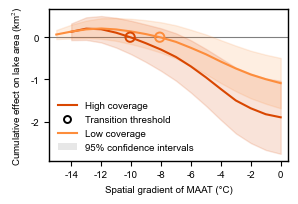

    saved: D:\Python39\Code-NG13\results\F3b.svg
[2] ITED 按 ICE 分层 -> F3d


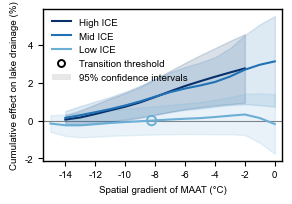

    saved: D:\Python39\Code-NG13\results\F3d.svg
[3] ITES 按 ICE 分层 -> F3e
  [High ICE] 动态阈值拐点 τ=+0.0479
  [Mid ICE] 动态阈值拐点 τ=+0.0980
  [Low ICE] 动态阈值拐点 τ=+0.0836


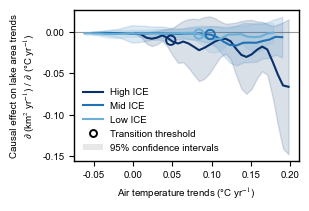

    saved: D:\Python39\Code-NG13\results\F3e.svg
[4] ITES 按 Lake coverage 分层 -> F3c
  [High coverage] 动态阈值拐点 τ=+0.0374
  [Low coverage] 动态阈值拐点 τ=+0.1425


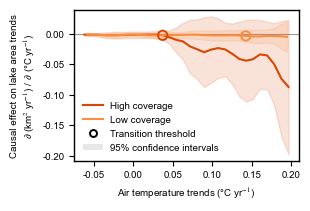

    saved: D:\Python39\Code-NG13\results\F3c.svg

全部完成，输出目录: D:\Python39\Code-NG13\results


In [9]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator, MaxNLocator, FormatStrFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import norm

warnings.filterwarnings('ignore')

# ---- 路径 ----
ITE_CSV   = r'D:\Python39\Code-NG13\results\ITE_ALL.csv'
OUT_DIR   = r'D:\Python39\Code-NG13\results'
os.makedirs(OUT_DIR, exist_ok=True)

# ---- 全局样式 ----
rcParams.update({
    "font.family": 'Arial', "font.size": 7, "axes.labelsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.unicode_minus": False,
    "mathtext.fontset": 'stix', "figure.dpi": 100, "savefig.dpi": 300,
    "legend.fontsize": 7, "svg.fonttype": "path"
})

# ---- 辅助函数 ----
def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

def build_binned_stats(df_sub, y_col, lo_col, hi_col, maat_range=(-16, 2), n_bins_step=1.0):
    d = df_sub.copy()
    if len(d) < 20: return None
    bins_t = np.arange(maat_range[0] - 1, maat_range[1] + 2, n_bins_step)
    d['TAS_bin'] = pd.cut(d['ERA_TAS'], bins=bins_t, right=True, include_lowest=True)
    d['TAS_bin_label'] = d['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
    d = d.dropna(subset=['TAS_bin_label']).copy()
    if len(d) == 0: return None
    d['TAS_bin_label'] = d['TAS_bin_label'].astype(int)
    b = d.groupby('TAS_bin_label', observed=True).agg(
        total_mean=(y_col, 'mean'), total_lower_mean=(lo_col, 'mean'),
        total_upper_mean=(hi_col, 'mean'), n=(y_col, 'size')
    ).reset_index().sort_values('TAS_bin_label')
    b = b[(b['TAS_bin_label'] >= maat_range[0]) & (b['TAS_bin_label'] <= maat_range[1])].reset_index(drop=True)
    if len(b) < 2: return None
    b['total_mean_smooth']       = simple_smooth(b['total_mean'], 3)
    b['total_lower_mean_smooth'] = simple_smooth(b['total_lower_mean'], 3)
    b['total_upper_mean_smooth'] = simple_smooth(b['total_upper_mean'], 3)
    b['cumsum'] = b['total_mean_smooth'].cumsum()
    se = np.clip((b['total_upper_mean_smooth'] - b['total_lower_mean_smooth']) / (2*1.96), 1e-12, None)
    se_cum = np.sqrt((se ** 2).cumsum())
    b['cumsum_lo'] = b['cumsum'] - 1.96 * se_cum
    b['cumsum_hi'] = b['cumsum'] + 1.96 * se_cum
    return b

def build_slope_binned_stats(df_sub, y_col, lo_col, hi_col, n_bins=30):
    d = df_sub.copy().dropna(subset=['ERA_TAS_slope'])
    if len(d) < 50: return None
    s_min, s_max = d['ERA_TAS_slope'].min(), d['ERA_TAS_slope'].max()
    if s_min == s_max: return None
    slope_bins = np.linspace(s_min, s_max, n_bins + 1)
    d['SLOPE_bin'] = pd.cut(d['ERA_TAS_slope'], bins=slope_bins, right=True, include_lowest=True)
    d['SLOPE_bin_label'] = d['SLOPE_bin'].apply(lambda x: 0.5 * (x.left + x.right) if pd.notna(x) else np.nan)
    d['SLOPE_bin_label'] = pd.to_numeric(d['SLOPE_bin_label'], errors='coerce')
    d = d.dropna(subset=['SLOPE_bin_label']).copy()

    b = d.groupby('SLOPE_bin_label', observed=True).agg(
        total_mean=(y_col, 'mean'), total_lower_mean=(lo_col, 'mean'),
        total_upper_mean=(hi_col, 'mean'), n=(y_col, 'size')
    ).reset_index().sort_values('SLOPE_bin_label')
    b = b[b['n'] >= 5].reset_index(drop=True)
    if len(b) < 3: return None
    b['total_mean_smooth']       = simple_smooth(b['total_mean'], 3)
    b['total_lower_mean_smooth'] = simple_smooth(b['total_lower_mean'], 3)
    b['total_upper_mean_smooth'] = simple_smooth(b['total_upper_mean'], 3)
    return b


def find_dynamic_shift_point(binned_stats, k_sigma=1.96):
    if binned_stats is None: return None, None
    x_vals = binned_stats['SLOPE_bin_label'].values.astype(float)
    y_vals = binned_stats['total_mean_smooth'].values.astype(float)
    
    n = len(y_vals)
    init_win = max(4, int(n * 0.15))
    if n < init_win: return None, None
    

    base_y = list(y_vals[:init_win])
    init_std = max(np.std(base_y), 0.0008) 
    

    end_idx = init_win
    for i in range(init_win, n):
        curr_mean = np.mean(base_y)
        thresh = curr_mean - k_sigma * init_std

        if i + 1 < n and y_vals[i] < thresh and y_vals[i+1] < thresh:
            break

        if y_vals[i] < thresh:
            continue
        base_y.append(y_vals[i])
        end_idx = i + 1
        
    if end_idx >= n: return None, None
        

    dynamic_base = np.mean(base_y)
    dynamic_std = np.std(base_y)
    dynamic_thresh = dynamic_base - k_sigma * dynamic_std
    

    for i in range(end_idx, n):
        if y_vals[i] < dynamic_thresh:
            subsequent = y_vals[i:]
            if len(subsequent) >= 3 and np.mean(subsequent < dynamic_thresh) >= 0.75:
                x1, x2 = x_vals[i-1], x_vals[i]
                y1, y2 = y_vals[i-1], y_vals[i]
                if y2 != y1:
                    tau = x1 + (dynamic_thresh - y1) * (x2 - x1) / (y2 - y1)
                    return max(x1, min(x2, tau)), dynamic_base
                else:
                    return x2, dynamic_base
    return None, None


def fieller_zero_cross_with_ci(binned_stats, mean_col='total_mean_smooth',
                                lo_col='total_lower_mean_smooth', hi_col='total_upper_mean_smooth',
                                search_min=-16, search_max=2, direction='neg_to_pos', alpha=0.05):
    df = binned_stats.copy()
    df['TAS_bin_label'] = pd.to_numeric(df['TAS_bin_label'], errors='coerce')
    df = df[(df['TAS_bin_label'] >= float(search_min)) & (df['TAS_bin_label'] <= float(search_max))].sort_values('TAS_bin_label').reset_index(drop=True)
    if len(df) < 2: return None, None, None
    x_vals = df['TAS_bin_label'].values.astype(float)
    mean_vals = df[mean_col].values
    lo_vals, hi_vals = df[lo_col].values, df[hi_col].values
    cumsum = np.cumsum(mean_vals)
    se_bin = np.clip((hi_vals - lo_vals) / (2 * 1.96), 1e-12, None)
    se_cumsum = np.sqrt(np.cumsum(se_bin ** 2))
    z = norm.ppf(1 - alpha / 2)
    for i in range(len(df) - 1):
        y1, y2 = cumsum[i], cumsum[i + 1]
        if np.sign(y1) == np.sign(y2): continue
        if direction == 'neg_to_pos' and not (y1 < 0 and y2 > 0): continue
        if direction == 'pos_to_neg' and not (y1 > 0 and y2 < 0): continue
        x1, x2 = x_vals[i], x_vals[i + 1]
        T_star = x1 - y1 * (x2 - x1) / (y2 - y1)
        SE_at_T = float(np.interp(T_star, x_vals, se_cumsum))
        F_prime = float(np.interp(T_star, x_vals, mean_vals))
        if abs(F_prime) < 1e-10: return T_star, None, None
        se_T = SE_at_T / abs(F_prime)
        return T_star, T_star - z * se_T, T_star + z * se_T
    return None, None, None

def fieller_zero_cross_bidirectional(binned_stats, mean_col, lo_col, hi_col, search_min=-16, search_max=2):
    results = []
    for direction in ['pos_to_neg', 'neg_to_pos']:
        T, T_lo, T_hi = fieller_zero_cross_with_ci(binned_stats, mean_col, lo_col, hi_col, search_min, search_max, direction)
        if T is not None:
            results.append(dict(direction=direction, T=T, T_lo=T_lo, T_hi=T_hi))
    return results


def plot_cumsum_curves(curves, save_path, ylabel, note=None, legend_loc='upper left', int_y=False):
    fig, ax = plt.subplots(figsize=(9.5/2.54, 5.5/2.54))
    plt.subplots_adjust(left=0.18, right=0.82, top=0.92, bottom=0.22)
    handles, labels = [], []
    crossing_handled = False

    for c in curves:
        b = c.get('binned_stats')
        if b is None: continue
        ln, = ax.plot(b['TAS_bin_label'], b['cumsum'], linestyle=c['linestyle'], color=c['color'], linewidth=1.5, label=c['name'])
        ax.fill_between(b['TAS_bin_label'], b['cumsum_lo'], b['cumsum_hi'], color=c['color'], alpha=0.15)
        handles.append(ln); labels.append(c['name'])
        
        cr = c.get('crossing')
        if cr is not None:
            ax.scatter(cr['T'], 0, edgecolor=c['color'], facecolor='none', s=45, linewidth=1.4, zorder=10)
            if not crossing_handled:
                proxy = Line2D([0], [0], marker='o', color='w', markerfacecolor='none', markeredgecolor='black', markersize=5, markeredgewidth=1.4, linestyle='None', label='Transition threshold')
                handles.append(proxy); labels.append('Transition threshold')
                crossing_handled = True

    ax.axhline(0, color='black', lw=0.8, alpha=0.5, zorder=0)
    ax.set_xlim(-15.5, 0.5)
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.set_xlabel('Spatial gradient of MAAT (°C)')
    ax.set_ylabel(ylabel)
    if int_y:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.yaxis.set_major_formatter(FormatStrFormatter('%d'))
    for sp in ax.spines.values(): sp.set_linewidth(1)
    ci_proxy = Patch(facecolor='#888888', alpha=0.2, edgecolor=None)
    handles.append(ci_proxy); labels.append('95% confidence intervals')
    ax.legend(handles, labels, loc=legend_loc, frameon=False)
    if note:
        ax.text(0.015, 0.02, note, transform=ax.transAxes, ha='left', va='bottom', fontsize=5.5, color='gray', style='italic')
    plt.savefig(save_path, format='svg', bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"    saved: {save_path}")

# ---- 绘图函数：ITES 剖面（动态阈值曲线打点） ----
def plot_slope_profile(curves, save_path, note=None):
    fig, ax = plt.subplots(figsize=(9.5/2.54, 5.5/2.54))
    plt.subplots_adjust(left=0.22, right=0.82, top=0.92, bottom=0.22)
    handles, labels = [], []
    has_threshold = False

    for c in curves:
        b = c.get('binned_stats')
        if b is None: continue
        x_bin = b['SLOPE_bin_label'].values.astype(float)
        y_bin = b['total_mean_smooth'].values.astype(float)
        color = c['color']
        
        ln, = ax.plot(x_bin, y_bin, linestyle='-', color=color, linewidth=1.5, label=c['name'])
        ax.fill_between(x_bin, b['total_lower_mean_smooth'], b['total_upper_mean_smooth'], color=color, alpha=0.15)
        handles.append(ln); labels.append(c['name'])

        tau_est, _ = find_dynamic_shift_point(b, k_sigma=1.96)
        
        if tau_est is not None:
            print(f"  [{c['name']}] 动态阈值拐点 τ={tau_est:+.4f}")
            
            y_at_tau = np.interp(tau_est, x_bin, y_bin)
            
            ax.scatter(tau_est, y_at_tau, edgecolor=color, facecolor='none', s=45, linewidth=1.4, zorder=10)
            has_threshold = True

    ax.axhline(0, color='black', linestyle='-', alpha=0.4, zorder=0, linewidth=0.8)
    
    ax.set_xlabel(r'Air temperature trends (°C yr$^{-1}$)')
    ax.set_ylabel('Causal effect on lake area trends\n$\partial$ (km$^{2}$ yr$^{-1}$) $/\,$ $\partial$ (°C yr$^{-1}$)')
    for sp in ax.spines.values(): sp.set_linewidth(1)
    
    if has_threshold:
        proxy_shift = Line2D([0], [0], marker='o', color='w', markerfacecolor='none', markeredgecolor='black', markersize=5, markeredgewidth=1.4, linestyle='None', label='Transition threshold')
        handles.append(proxy_shift); labels.append('Transition threshold')
    ci_proxy = Patch(facecolor='#888888', alpha=0.2, edgecolor=None)
    handles.append(ci_proxy); labels.append('95% confidence intervals')
    ax.legend(handles, labels, loc='lower left', frameon=False)
    if note:
        ax.text(0.015, 0.02, note, transform=ax.transAxes, ha='left', va='bottom', fontsize=5.5, color='gray', style='italic')
    plt.savefig(save_path, format='svg', bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"    saved: {save_path}")

# ===================== 执行主流程 =====================
print("===== 读取数据并分组 =====")
df_s = pd.read_csv(ITE_CSV, encoding='utf-8-sig')

ICE_MAP = {3: 'High ICE', 2: 'Mid ICE', 1: 'Low ICE'}
df_s['ICE_group'] = df_s['ICE'].map(ICE_MAP)
df_s['COV_group'] = np.where(df_s['Lake_density'] <= 0.05, 'Low coverage', 'High coverage')

ICE_COLORS = {'High ICE': '#08306b', 'Mid ICE': '#2171b5', 'Low ICE': '#6baed6'}
ICE_ORDER  = ['High ICE', 'Mid ICE', 'Low ICE']
COV_COLORS = {'High coverage': '#d94701', 'Low coverage': '#fd8d3c'}
COV_ORDER  = ['High coverage', 'Low coverage']
DIRECTION_MAP = {'ITEA': 'pos_to_neg', 'ITED': 'neg_to_pos'}

def plot_cumsum_by_group(seg, group_col, color_map, group_order, save_name, note=None, legend_loc='upper left', int_y=False):
    if seg == 'ITED':
        df_use = df_s.copy()
        df_use[f'{seg}_pct'] = df_use[seg] * 100
        df_use[f'{seg}_pct_u'] = df_use[seg + '_u'] * 100
        df_use[f'{seg}_pct_d'] = df_use[seg + '_d'] * 100
        y_col, lo_col, hi_col = f'{seg}_pct', f'{seg}_pct_d', f'{seg}_pct_u'
    else:
        df_use = df_s
        y_col, lo_col, hi_col = seg, f'{seg}_d', f'{seg}_u'

    pref_dir = DIRECTION_MAP[seg]
    curves = []
    for g in group_order:
        gsub = df_use[df_use[group_col] == g].copy()
        if len(gsub) < 50: continue
        b = build_binned_stats(gsub, y_col, lo_col, hi_col)
        if b is not None:
            crossings = fieller_zero_cross_bidirectional(b, 'total_mean_smooth', 'total_lower_mean_smooth', 'total_upper_mean_smooth')
            cr = next((c for c in crossings if c['direction'] == pref_dir), None)
        else:
            cr = None
        curves.append(dict(name=g, color=color_map[g], linestyle='-', binned_stats=b, crossing=cr))
    y_label = r'Cumulative effect on lake area (km$^{2}$)' if seg == 'ITEA' else 'Cumulative effect on lake drainage (%)'
    save_path = os.path.join(OUT_DIR, f'{save_name}.svg')
    plot_cumsum_curves(curves, save_path, y_label, note, legend_loc=legend_loc, int_y=int_y)

def plot_ites_by_group(group_col, color_map, group_order, save_name, note=None):
    curves = []
    for g in group_order:
        gsub = df_s[df_s[group_col] == g].copy()
        b = build_slope_binned_stats(gsub, 'ITES', 'ITES_d', 'ITES_u')
        curves.append(dict(name=g, color=color_map[g], binned_stats=b))
    save_path = os.path.join(OUT_DIR, f'{save_name}.svg')
    plot_slope_profile(curves, save_path, note)

print("\n[1] ITEA 按 Lake coverage 分层 -> F3b")
plot_cumsum_by_group('ITEA', 'COV_group', COV_COLORS, COV_ORDER, save_name='F3b', legend_loc='lower left', int_y=True)
print("[2] ITED 按 ICE 分层 -> F3d")
plot_cumsum_by_group('ITED', 'ICE_group', ICE_COLORS, ICE_ORDER, save_name='F3d')
print("[3] ITES 按 ICE 分层 -> F3e")
plot_ites_by_group('ICE_group', ICE_COLORS, ICE_ORDER, save_name='F3e')
print("[4] ITES 按 Lake coverage 分层 -> F3c")
plot_ites_by_group('COV_group', COV_COLORS, COV_ORDER, save_name='F3c')
print(f"\n全部完成，输出目录: {OUT_DIR}")